# Degradation features

Builds the engineered features from `rul.features.make_features` on the FD001 **training** engines,
inspects them, and runs an ablation with a Random Forest on 5 fold `engine_folds`.
The test set is not used here.

Features added per sensor (after per regime normalisation with training statistics):
rolling mean and std, and the least squares rolling slope, over windows of 5, 10 and 20 cycles,
always computed inside one engine. A health index (0 to 1) combines all sensors.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

from rul.data import USEFUL_SENSORS, add_rul, load_fd
from rul.evaluate import evaluate
from rul.features import feature_groups, make_features
from rul.split import engine_folds

SEED = 42
WINDOWS = (5, 10, 20)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.precision", 3)

## Load training engines and the capped RUL target

In [2]:
train, _, _ = load_fd("FD001")  # only the training engines are used below
train = add_rul(train, cap=125)
sensors = USEFUL_SENSORS
groups = feature_groups(sensors, WINDOWS)
print(train.shape, "engines:", train.unit.nunique(), "sensors:", len(sensors))

(20631, 27) engines: 100 sensors: 14


## Build features on all training engines (for inspection only)

The scaler here is fitted on every training engine. That is fine for plots, but the ablation
below refits it inside each fold on the training engines of that fold only.

In [3]:
feats, scaler = make_features(train, sensors, WINDOWS)
print("rows in / out:", len(train), len(feats), "| index kept:", feats.index.equals(train.index))
print("NaN cells:", int(feats.isna().sum().sum()))
print("operating regimes:", feats.regime.nunique())
print({name: len(cols) for name, cols in groups.items()})

rows in / out: 20631 20631 | index kept: True
NaN cells: 0
operating regimes: 1
{'raw': 15, 'regime': 1, 'norm': 14, 'rolling': 84, 'slope': 42, 'health': 1}


## Correlation with RUL

The features use the 14 `USEFUL_SENSORS` chosen in the exploratory analysis (`01_eda.ipynb`), which already drops the constant
sensors and the near binary s_6. These correlations are **in sample**: the
scaler and health index were fitted on the same engines. The out of fold health index correlation
is computed in the ablation below. Each row is a sensor, each column a feature family at the
widest window.

health_index vs RUL, in sample: 0.864


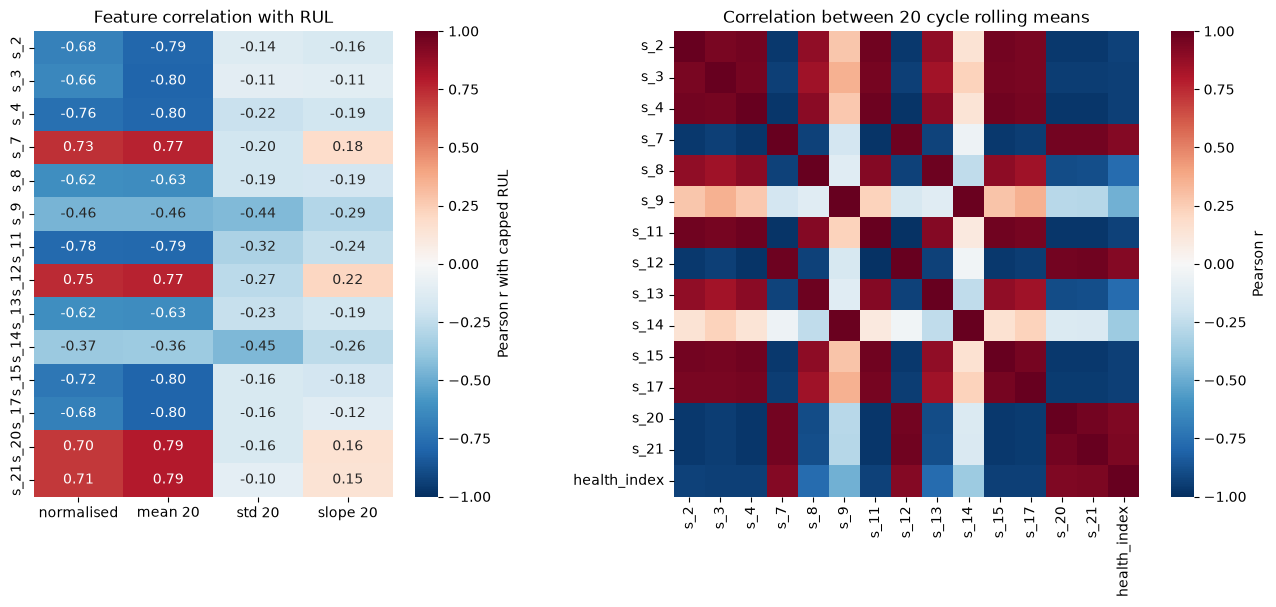

In [4]:
varying = [s for s in sensors if train[s].std() > 1e-8]
cols = {"normalised": "{s}_norm", "mean 20": "{s}_mean_20", "std 20": "{s}_std_20",
        "slope 20": "{s}_slope_20"}
corr = pd.DataFrame({name: [feats[pat.format(s=s)].corr(feats.rul) for s in varying]
                     for name, pat in cols.items()}, index=varying)
print("health_index vs RUL, in sample:", round(feats.health_index.corr(feats.rul), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.4]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0],
            cbar_kws={"label": "Pearson r with capped RUL"})
axes[0].set_title("Feature correlation with RUL")
between = feats[[f"{s}_mean_20" for s in varying] + ["health_index"]].corr()
between.index = between.columns = [c.replace("_mean_20", "") for c in between.columns]
sns.heatmap(between, cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1], square=True,
            cbar_kws={"label": "Pearson r"})
axes[1].set_title("Correlation between 20 cycle rolling means")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "features_correlation.png", dpi=150)
plt.show()

## Rolling trends and slopes against cycle

Two engines, two sensors that rise with wear (s_11) and fall with wear (s_12). The 20 cycle rolling
mean smooths sensor noise. The 20 cycle slope is the local degradation rate: near 0 while the engine
is healthy, then growing in magnitude as it nears failure. For the first 19 cycles the window is
partial (`min_periods=1`), and a slope fitted to 2 or 3 noisy points is large and meaningless, so
the slope axis is scaled to cycles 20 onwards. The health index falls towards 0 at failure; it starts
near 0.8 rather than 1 because the first half of life looks alike in the sensors.

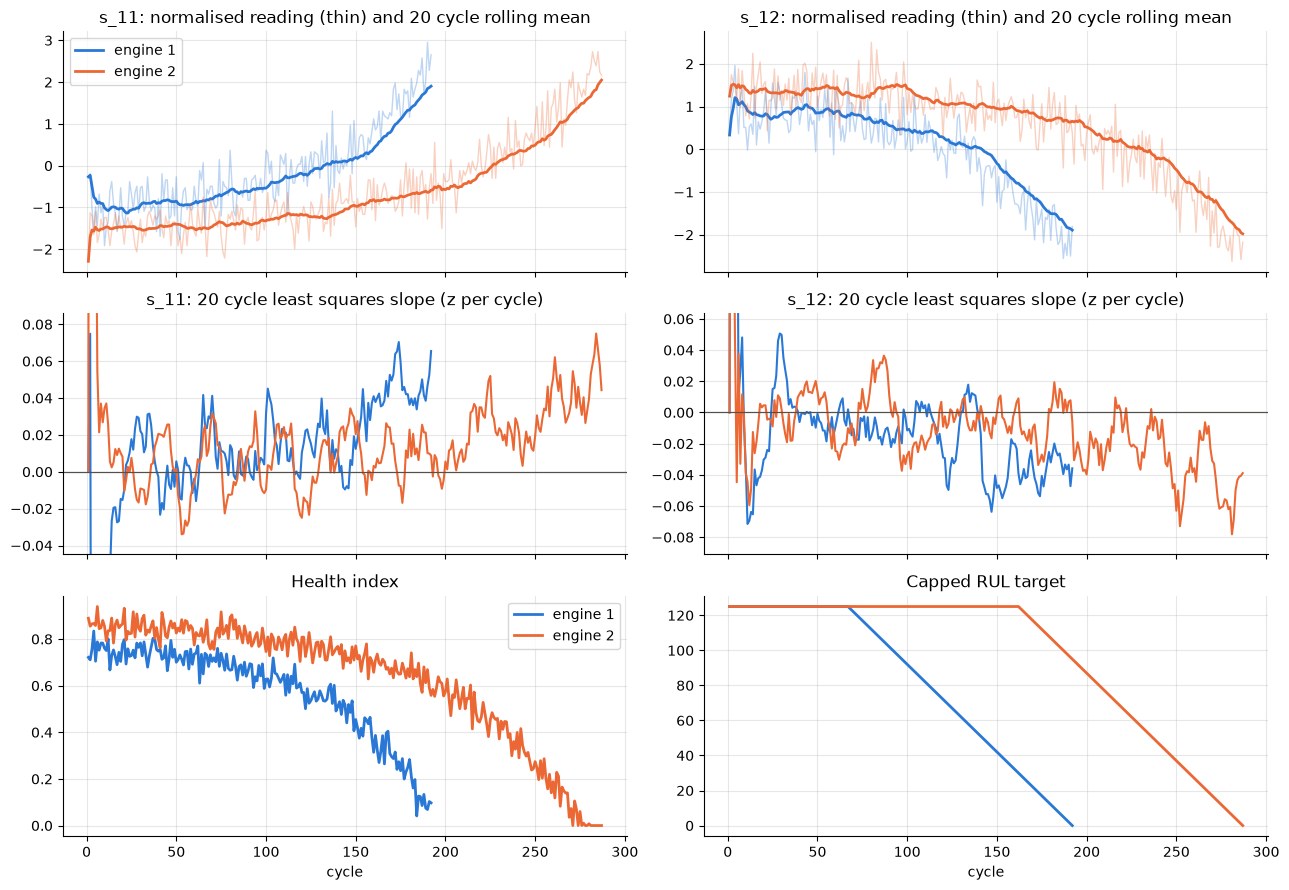

In [5]:
colors = {1: "#2a78d6", 2: "#eb6834"}
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
for unit, color in colors.items():
    e = feats[feats.unit == unit]
    for col, s in enumerate(["s_11", "s_12"]):
        axes[0, col].plot(e.cycle, e[f"{s}_norm"], color=color, alpha=0.3, lw=1)
        axes[0, col].plot(e.cycle, e[f"{s}_mean_20"], color=color, lw=2, label=f"engine {unit}")
        axes[0, col].set_title(f"{s}: normalised reading (thin) and 20 cycle rolling mean")
        axes[1, col].plot(e.cycle, e[f"{s}_slope_20"], color=color, lw=1.5)
        axes[1, col].set_title(f"{s}: 20 cycle least squares slope (z per cycle)")
        settled = feats.loc[feats.unit.isin(colors) & (feats.cycle >= 20), f"{s}_slope_20"]
        pad = 0.1 * (settled.max() - settled.min())
        axes[1, col].set_ylim(settled.min() - pad, settled.max() + pad)
        axes[1, col].axhline(0, color="#52514e", lw=0.8)
    axes[2, 0].plot(e.cycle, e.health_index, color=color, lw=2, label=f"engine {unit}")
    axes[2, 1].plot(e.cycle, e.rul, color=color, lw=2, label=f"engine {unit}")
axes[2, 0].set_title("Health index")
axes[2, 1].set_title("Capped RUL target")
for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend()
axes[2, 0].legend()
for ax in axes[2]:
    ax.set_xlabel("cycle")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "features_degradation_trends.png", dpi=150)
plt.show()

## Ablation: what each feature family adds

**Model:** a default `RandomForestRegressor(random_state=42)`, so the comparison reflects the
features rather than hyperparameter tuning.

Scored on 5 fold `engine_folds`. In every fold
`make_features` is fitted on the training engines of the fold and only applied to the validation
engines, so no validation statistics leak into the regime moments or the health index.
Every validation cycle is scored against the capped RUL; NASA score is the sum over those cycles.
The loop also records the **out of fold** health index correlation: the HI is fitted on each fold's
training engines and correlated with RUL on its validation engines.

In [6]:
configs = {
    "1. raw sensors": groups["raw"],
    "2. + rolling mean and std": groups["raw"] + groups["rolling"],
    "3. + rolling slopes": groups["raw"] + groups["rolling"] + groups["slope"],
    "4. + health index": groups["raw"] + groups["rolling"] + groups["slope"] + groups["health"],
}
folds = engine_folds(train, n_splits=5)
rows, hi_corr = [], []
for k, (tr_idx, va_idx) in enumerate(folds):
    fold_train, fold_val = train.iloc[tr_idx], train.iloc[va_idx]
    f_train, fold_scaler = make_features(fold_train, sensors, WINDOWS)
    f_val, _ = make_features(fold_val, sensors, WINDOWS, scaler=fold_scaler)
    hi_corr.append(f_val.health_index.corr(f_val.rul))
    for name, cols in configs.items():
        model = RandomForestRegressor(random_state=SEED, n_jobs=-1)
        model.fit(f_train[cols], f_train.rul)
        scores = evaluate(f_val.rul, model.predict(f_val[cols]))
        rows.append({"config": name, "fold": k, "n_features": len(cols), **scores})
cv = pd.DataFrame(rows)
hi_corr = pd.Series(hi_corr, name="out of fold r(health_index, rul)").rename_axis("fold")
hi_corr.to_frame().to_csv(ROOT / "results" / "features_hi_correlation.csv")
print(f"health_index vs RUL, out of fold: {hi_corr.mean():.3f} +/- {hi_corr.std():.3f}")
print(hi_corr.round(3).to_string())

health_index vs RUL, out of fold: 0.868 +/- 0.016
fold
0    0.851
1    0.868
2    0.872
3    0.893
4    0.856


In [7]:
ablation = cv.groupby("config").agg(
    n_features=("n_features", "first"),
    rmse_mean=("rmse", "mean"), rmse_std=("rmse", "std"),
    mae_mean=("mae", "mean"), mae_std=("mae", "std"),
    nasa_score_mean=("nasa_score", "mean"),
    rmse_late_mean=("rmse_late", "mean"),
)
ablation.to_csv(ROOT / "results" / "features_ablation.csv")
ablation

,n_features,rmse_mean,rmse_std,mae_mean,mae_std,nasa_score_mean,rmse_late_mean
config,,,,,,,
1. raw sensors,15,16.806,0.779,11.527,0.636,26573.040,15.539
2. + rolling mean and std,99,16.359,0.774,11.039,0.691,23477.897,13.857
3. + rolling slopes,141,14.778,0.489,10.037,0.525,17178.760,11.371
4. + health index,142,14.740,0.560,9.967,0.614,16927.704,11.243


Reading the table (numbers are in the output above and in `results/features_ablation.csv`):

* **Rolling mean and std** give a modest gain over raw sensors. Averaging removes per cycle noise,
  but a Random Forest already averages over many noisy rows, so smoothing alone helps only a little.
* **Rolling slopes** give the largest drop in RMSE, MAE and NASA score, and the clearest gain in the
  late stage (true RUL at most 50), where the rate of degradation is what separates an engine with
  30 cycles left from one with 10. The level of a sensor says how worn the engine is; the slope says
  how fast it is wearing.
* **The health index** adds a small further gain. It is a linear summary of sensors the forest can
  already see, so most of its information is already present; its value is as one interpretable
  number that summarises engine condition.

Fold to fold spread (std) is about 0.5 to 0.8 RMSE, so the slope gain is well outside the noise while
the health index gain is within it. Per fold RMSE:

In [8]:
cv.pivot(index="fold", columns="config", values="rmse")

config,1. raw sensors,2. + rolling mean and std,3. + rolling slopes,4. + health index
fold,,,,
0,17.516,16.829,15.168,15.445
1,16.622,16.611,15.078,14.634
2,17.155,16.335,14.706,15.000
3,15.537,15.044,13.961,13.918
4,17.200,16.977,14.977,14.703
